# Stage 2: Data Splitting, Traditional ML Models & Cross-Validation

**Student 2 - Traditional ML & Splitting**

This notebook takes the cleaned dataset from Stage 1 and:

1. Splits it into **Train (70%) / Validation (15%) / Test (15%)** with stratification on `Revenue`.
2. Builds a leak-free preprocessing pipeline (scaling + one-hot encoding fitted on training data only).
3. Builds and tunes two traditional models: **Random Forest** and **Support Vector Machine (SVM)**.
4. Uses **stratified k-fold cross-validation** for tuning and for estimating how stable each model is.
5. Compares both models on the validation set, then reports final results on the held-out test set.

In [ ]:
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("../plots", exist_ok=True)
os.makedirs("../data/splits", exist_ok=True)
os.makedirs("../models", exist_ok=True)

## 1. Load the cleaned dataset

In [ ]:
df = pd.read_csv("../data/online_shoppers_cleaned.csv")
print("Shape:", df.shape)
print("\nClass balance (Revenue):")
print(df["Revenue"].value_counts().to_frame("count").assign(
    percent=lambda t: (100 * t["count"] / t["count"].sum()).round(2)))
df.head()

Shape: (12205, 18)

Class balance (Revenue):
         count  percent
Revenue                
0        10297    84.37
1         1908    15.63


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


## 2. Train / Validation / Test split (70 / 15 / 15)

The target is imbalanced (~15% purchases), so every split is **stratified** on `Revenue` to keep the same class ratio in each set.
The split is done in two steps: first 70% train vs 30% temp, then the temp set is split in half into validation and test.

In [3]:
TARGET = "Revenue"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Share (%)": [round(100 * len(s) / len(X), 1) for s in (X_train, X_val, X_test)],
    "Purchase rate (%)": [round(100 * s.mean(), 2) for s in (y_train, y_val, y_test)],
}, index=["Train", "Validation", "Test"])
split_summary

,Rows,Share (%),Purchase rate (%)
Train,8543,70.0,15.64
Validation,1831,15.0,15.62
Test,1831,15.0,15.62


Save the splits so the rest of the team (e.g. the deep learning model) uses **exactly the same** rows.

In [4]:
for name, Xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    Xs.assign(**{TARGET: ys}).to_csv(f"../data/splits/{name}.csv", index=False)
print(os.listdir("../data/splits"))

['val.csv', 'test.csv', 'train.csv']


## 3. Preprocessing pipeline

* **Numeric features** -> `StandardScaler` (important for SVM, harmless for Random Forest).
* **Categorical features** (`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`) -> `OneHotEncoder`.
  These columns are numeric codes in the data but they are labels, not quantities, so they are one-hot encoded.
* `Weekend` is already 0/1 and passes through.

The preprocessor lives **inside** each model pipeline, so during cross-validation it is re-fitted on each training fold only. That prevents data leakage from validation folds.

In [5]:
categorical_cols = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
binary_cols = ["Weekend"]
numeric_cols = [c for c in X.columns if c not in categorical_cols + binary_cols]
print("Numeric:", numeric_cols)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("bin", "passthrough", binary_cols),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "f1"  # F1 on the purchase class: accuracy is misleading with a 85/15 imbalance

Numeric: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


## 4. Baselines (default hyperparameters)

Before tuning, both models are evaluated with default settings using 5-fold CV on the training set. This gives a reference point to show what tuning adds.
`class_weight="balanced"` is used so the models don't ignore the minority (purchase) class.

In [6]:
baselines = {
    "Random Forest (default)": Pipeline([("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]),
    "SVM (default)": Pipeline([("prep", make_preprocessor()),
        ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
}
baseline_rows = {}
for name, pipe in baselines.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "roc_auc", "accuracy"], n_jobs=-1)
    baseline_rows[name] = {k.replace("test_", "CV "): f"{v.mean():.4f} ± {v.std():.4f}"
                           for k, v in s.items() if k.startswith("test_")}
pd.DataFrame(baseline_rows).T

,CV f1,CV roc_auc,CV accuracy
Random Forest (default),0.6733 ± 0.0158,0.9254 ± 0.0064,0.8920 ± 0.0038
SVM (default),0.6518 ± 0.0191,0.9027 ± 0.0054,0.8732 ± 0.0065


## 5. Model 1: Random Forest - hyperparameter tuning

`RandomizedSearchCV` (60 candidates x 5 folds) over the main Random Forest hyperparameters:

| Hyperparameter | Meaning |
|---|---|
| `n_estimators` | number of trees |
| `max_depth` | maximum depth of each tree (controls overfitting) |
| `min_samples_split` / `min_samples_leaf` | minimum samples needed to split / to form a leaf |
| `max_features` | number of features considered at each split |
| `class_weight` | how to re-weight the minority class |

In [7]:
rf_pipe = Pipeline([("prep", make_preprocessor()),
                    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

rf_param_dist = {
    "clf__n_estimators": randint(100, 600),
    "clf__max_depth": [None, 5, 10, 15, 20, 30],
    "clf__min_samples_split": randint(2, 20),
    "clf__min_samples_leaf": randint(1, 10),
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
}

rf_search = RandomizedSearchCV(rf_pipe, rf_param_dist, n_iter=60, scoring=SCORING, cv=cv,
                               n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
t0 = time.time()
rf_search.fit(X_train, y_train)
print(f"Search time: {time.time() - t0:.1f}s")
print(f"Best CV F1: {rf_search.best_score_:.4f}")
print("Best params:")
for k, v in rf_search.best_params_.items():
    print(f"  {k.replace('clf__', '')}: {v}")

Search time: 134.3s
Best CV F1: 0.6845
Best params:
  class_weight: balanced_subsample
  max_depth: 30
  max_features: 0.5
  min_samples_leaf: 3
  min_samples_split: 5
  n_estimators: 502


In [8]:
rf_results = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
cols = [c for c in rf_results.columns if c.startswith("param_")] + ["mean_train_score", "mean_test_score", "std_test_score"]
rf_results[cols].head(10).rename(columns=lambda c: c.replace("param_clf__", ""))

,class_weight,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,mean_train_score,mean_test_score,std_test_score
40,balanced_subsample,30,0.5,3,5,502,0.929794,0.684544,0.012862
2,balanced_subsample,30,sqrt,2,13,513,0.845035,0.683282,0.017764
48,balanced_subsample,None,0.5,4,7,203,0.884689,0.681073,0.010027
51,balanced_subsample,20,sqrt,4,2,167,0.808438,0.678921,0.017359
44,balanced_subsample,30,log2,3,8,351,0.827305,0.678399,0.017071
45,balanced,None,0.5,1,3,484,0.963579,0.676523,0.010483
47,balanced_subsample,10,0.5,3,2,507,0.807687,0.675611,0.015324
9,balanced_subsample,15,0.3,8,16,134,0.765928,0.675427,0.014009
22,balanced_subsample,30,0.3,1,6,317,0.981337,0.673767,0.009510
31,balanced_subsample,30,0.5,9,6,324,0.771827,0.673441,0.012348


## 6. Model 2: Support Vector Machine - hyperparameter tuning

`GridSearchCV` over kernel, `C` (regularisation strength) and `gamma` (RBF kernel width).
Small `C` = wider margin / more regularisation; large `gamma` = more complex decision boundary.

In [9]:
svm_pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", SVC(class_weight="balanced", probability=False, random_state=RANDOM_STATE))])

svm_param_grid = [
    {"clf__kernel": ["rbf"],
     "clf__C": [0.1, 0.5, 1, 5, 10, 50],
     "clf__gamma": ["scale", 0.001, 0.01, 0.05, 0.1]},
    {"clf__kernel": ["linear"],
     "clf__C": [0.01, 0.1, 1, 10]},
]

svm_search = GridSearchCV(svm_pipe, svm_param_grid, scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.time()
svm_search.fit(X_train, y_train)
print(f"Search time: {time.time() - t0:.1f}s")
print(f"Best CV F1: {svm_search.best_score_:.4f}")
print("Best params:")
for k, v in svm_search.best_params_.items():
    print(f"  {k.replace('clf__', '')}: {v}")

Search time: 69.6s
Best CV F1: 0.6603
Best params:
  C: 5
  gamma: 0.01
  kernel: rbf


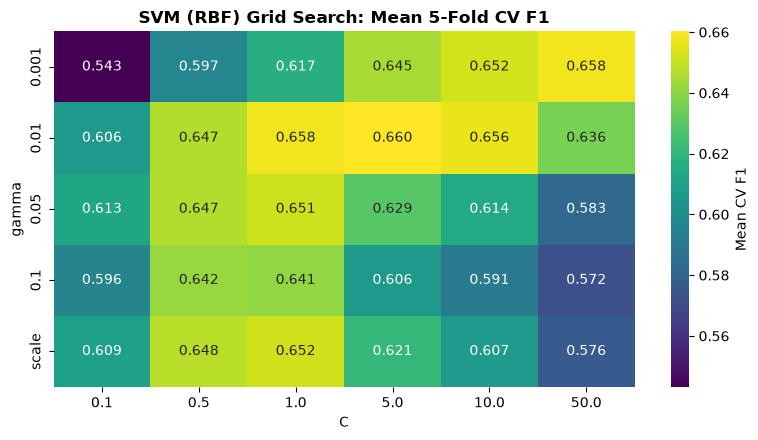

In [10]:
svm_results = pd.DataFrame(svm_search.cv_results_)
rbf = svm_results[svm_results["param_clf__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_clf__gamma"].astype(str)
heat = rbf.pivot_table(index="gamma", columns="param_clf__C", values="mean_test_score")

plt.figure(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "Mean CV F1"})
plt.title("SVM (RBF) Grid Search: Mean 5-Fold CV F1", fontsize=12, fontweight="bold")
plt.xlabel("C")
plt.ylabel("gamma")
plt.tight_layout()
plt.savefig("../plots/fig6_svm_gridsearch_heatmap.png", dpi=300)
plt.show()

## 7. Cross-validation of the tuned models

The tuned models are re-evaluated with **10-fold stratified cross-validation** on the training set across several metrics.
This shows both the expected performance (mean) and its stability (standard deviation) across folds.

In [11]:
best_rf = rf_search.best_estimator_
best_svm = svm_search.best_estimator_
tuned = {"Random Forest": best_rf, "SVM": best_svm}

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_scores, cv_long = {}, []
for name, model in tuned.items():
    s = cross_validate(model, X_train, y_train, cv=cv10, scoring=metrics, n_jobs=-1)
    cv_scores[name] = {m: f"{s['test_' + m].mean():.4f} ± {s['test_' + m].std():.4f}" for m in metrics}
    for m in metrics:
        cv_long += [{"Model": name, "Metric": m, "Score": v} for v in s["test_" + m]]

cv_table = pd.DataFrame(cv_scores).T
cv_table

,accuracy,precision,recall,f1,roc_auc
Random Forest,0.8973 ± 0.0076,0.6605 ± 0.0233,0.7081 ± 0.0323,0.6832 ± 0.0239,0.9317 ± 0.0061
SVM,0.8763 ± 0.0089,0.5789 ± 0.0225,0.7679 ± 0.0292,0.6600 ± 0.0239,0.9108 ± 0.0060


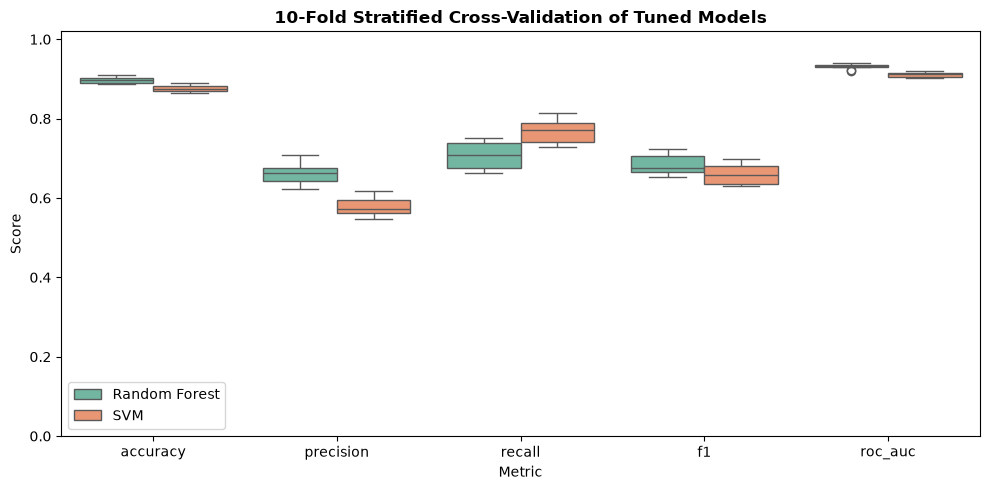

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=pd.DataFrame(cv_long), x="Metric", y="Score", hue="Model", palette="Set2")
plt.title("10-Fold Stratified Cross-Validation of Tuned Models", fontsize=12, fontweight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.02)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("../plots/fig7_cv_boxplot.png", dpi=300)
plt.show()

## 8. Validation set evaluation (model selection)

Both tuned models are fitted on the full training set and evaluated on the **validation** set, which was never used for tuning.

In [13]:
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    # SVM has no probabilities (probability=False), so ROC-AUC uses its decision function instead
    score = model.decision_function(X_) if isinstance(model[-1], SVC) else model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "ROC-AUC": roc_auc_score(y_, score)}

val_table = pd.DataFrame({name: evaluate(m, X_val, y_val) for name, m in tuned.items()}).T.round(4)
val_table

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.8946,0.6566,0.6818,0.6690,0.9303
SVM,0.8646,0.5487,0.7483,0.6331,0.9024


In [14]:
best_name = val_table["F1"].idxmax()
print(f"Selected model (highest validation F1): {best_name}")

Selected model (highest validation F1): Random Forest


## 9. Final evaluation on the test set

The test set is used **once**, only after all tuning and model selection decisions are made.
Both models are reported for comparison; the selected model is highlighted above.

In [15]:
test_table = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in tuned.items()}).T.round(4)
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.9011,0.6744,0.7098,0.6917,0.9269
SVM,0.8760,0.5791,0.7552,0.6555,0.9060


In [16]:
for name, m in tuned.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, m.predict(X_test), target_names=["No Purchase", "Purchase"], digits=4))

Random Forest
              precision    recall  f1-score   support

 No Purchase     0.9458    0.9366    0.9411      1545
    Purchase     0.6744    0.7098    0.6917       286

    accuracy                         0.9011      1831
   macro avg     0.8101    0.8232    0.8164      1831
weighted avg     0.9034    0.9011    0.9022      1831

SVM


              precision    recall  f1-score   support

 No Purchase     0.9520    0.8984    0.9244      1545
    Purchase     0.5791    0.7552    0.6555       286

    accuracy                         0.8760      1831
   macro avg     0.7655    0.8268    0.7900      1831
weighted avg     0.8937    0.8760    0.8824      1831



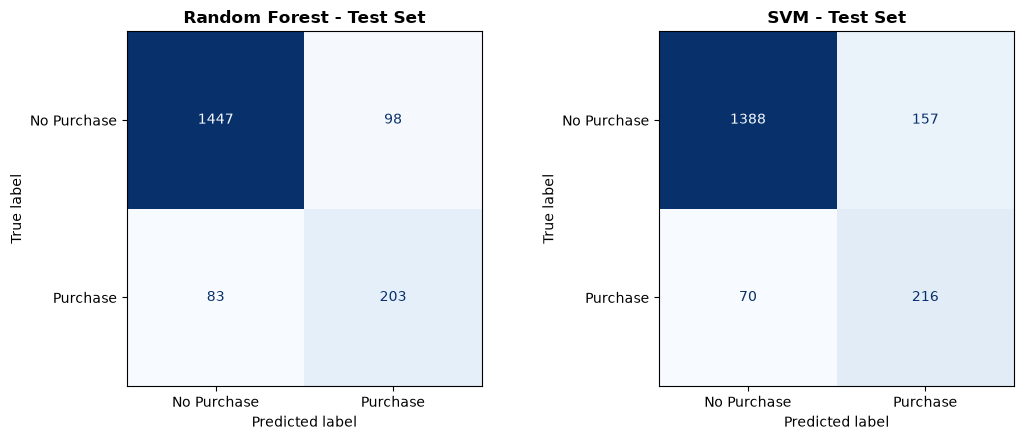

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["No Purchase", "Purchase"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name} - Test Set", fontweight="bold")
plt.tight_layout()
plt.savefig("../plots/fig8_confusion_matrices.png", dpi=300)
plt.show()

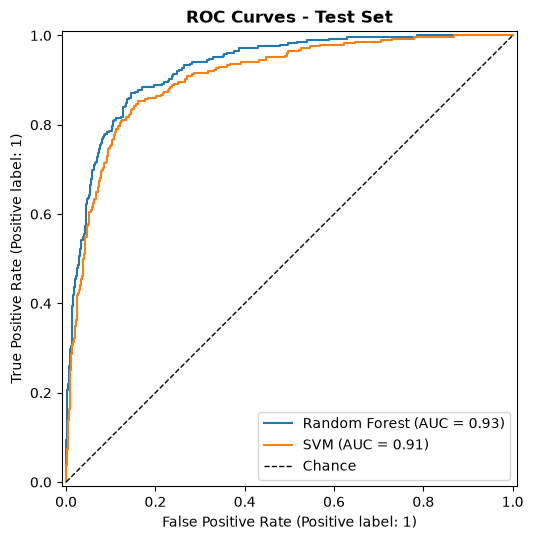

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_title("ROC Curves - Test Set", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../plots/fig9_roc_curves.png", dpi=300)
plt.show()

## 10. Random Forest feature importance (tuned model)

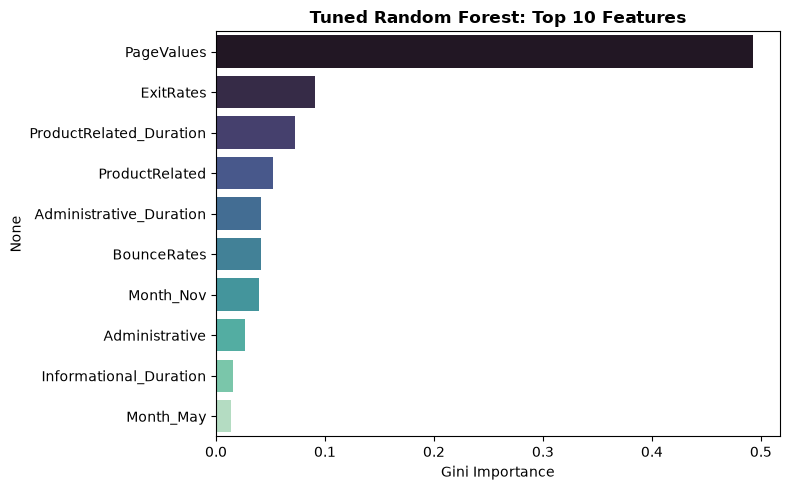

In [19]:
feat_names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["clf"].feature_importances_, index=feat_names)
imp.index = imp.index.str.replace(r"^(num|cat|bin)__", "", regex=True)
top = imp.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, hue=top.index, palette="mako", legend=False)
plt.title("Tuned Random Forest: Top 10 Features", fontsize=12, fontweight="bold")
plt.xlabel("Gini Importance")
plt.tight_layout()
plt.savefig("../plots/fig10_tuned_rf_importance.png", dpi=300)
plt.show()

## 11. Save models and results

In [20]:
joblib.dump(best_rf, "../models/random_forest_tuned.joblib", compress=3)
joblib.dump(best_svm, "../models/svm_tuned.joblib")

summary = pd.concat({"CV (10-fold, train)": cv_table, "Validation": val_table.astype(str), "Test": test_table.astype(str)}, axis=1)
summary.to_csv("../data/stage2_results_summary.csv")
print("Saved models to ../models/ and results to ../data/stage2_results_summary.csv")

Saved models to ../models/ and results to ../data/stage2_results_summary.csv


## 12. Summary

* Data split 70/15/15 with stratification; the class ratio is preserved in every split and the splits are saved in `data/splits/` for the other stages.
* Preprocessing (scaling + one-hot encoding) is inside the model pipeline, so cross-validation is leak-free.
* Both models were tuned with 5-fold stratified CV optimising **F1** of the purchase class (accuracy alone would reward predicting "no purchase" for everyone).
* 10-fold CV shows each tuned model's mean performance and its variance across folds.
* The validation set was used to choose the final model, and the test set was used only once for the final numbers.
* `PageValues` is the strongest predictor of a purchase by a large margin, matching the Stage 1 EDA.